# First leading the needed libraries

In [143]:
import pandas as pd
import numpy as np
import matplotlib.image as mpimg
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, pair_confusion_matrix
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from tqdm import tqdm

# Next loading the cleaned network flow data frame.

In [2]:
cleanDf = pd.read_csv(f'../data/processed/cicids2017_clean.csv')
cleanDf.head(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file,is_attack
0,49188,4,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
1,49188,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
2,49486,3,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
3,49486,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
4,88,609,7,4,484,414,233,0,69.142857,111.967895,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0


# Next just to center this NB and its objective, this is the research question we are aiming to use k-means clustering to solve


Relationship / pattern
Do the four behavioral groups seen in the exploratory analysis hold up when individual flows are clustered, and are the overlapping pairs (Web Attack – Brute Force vs. XSS; Bot vs. BENIGN) separable at the flow level at all?

### And this is the figure that depicts the four behavior groups.

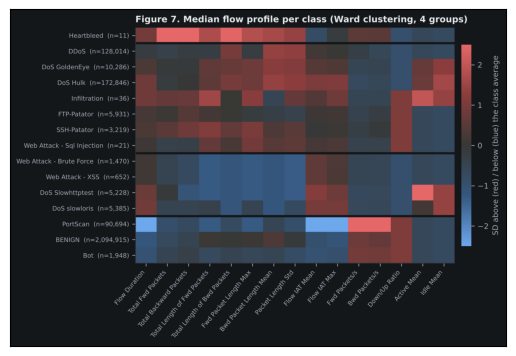

In [3]:
plt.imshow(mpimg.imread("../figures/rq3-class-profiles-dark.png"))
plt.xticks([])
plt.yticks([])
plt.show()

In [4]:
expected_groups = {"Heartbleed": "A",
         "DDoS": "B", "DoS GoldenEye": "B", "DoS Hulk": "B", "Infiltration": "B",
         "FTP-Patator": "B", "SSH-Patator": "B", "Web Attack - Sql Injection": "B",
         "Web Attack - Brute Force": "C", "Web Attack - XSS": "C",
         "DoS Slowhttptest": "C", "DoS slowloris": "C",
         "PortScan": "D", "BENIGN": "D", "Bot": "D"}


So if the initially derived four behavioral groups do, in fact, hold up. We would expect to see the following groups
- BENIGN, Bot, PortScan
- Dos Slowloris, DoS Slowhttptest, Web Attack - XSS , Web Attack - Brute Forice
- Web Attack - Sql Injection,SSH-Patator, FTP-Patator, Infiltration, DoS Hulk, DoS GoldenEye, DDoS
- Heartbleed

# Next we are going to standardize the columns and select only the behavior columns.

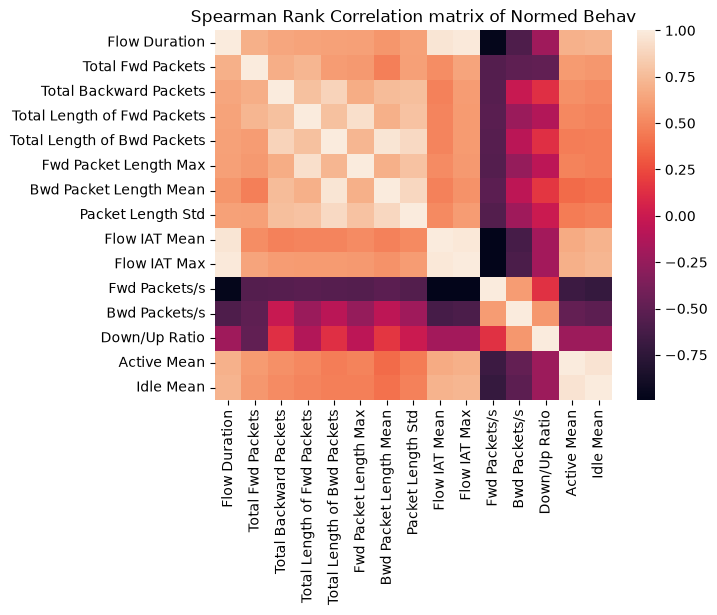

In [5]:
# BEHAVIORAL FEATURES ONLY: NO PORT, NO -1-CODED WINDOW FIELDS, NO 0/1 FLAGS
behav_cols = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
               "Total Length of Fwd Packets", "Total Length of Bwd Packets",
               "Fwd Packet Length Max", "Bwd Packet Length Mean", "Packet Length Std",
               "Flow IAT Mean", "Flow IAT Max", "Fwd Packets/s", "Bwd Packets/s",
               "Down/Up Ratio", "Active Mean", "Idle Mean"]

flow_clust_df = cleanDf[behav_cols]

# MEDIAN OF LOG10(1 + VALUE) PER CLASS: MEDIAN BECAUSE SKEWED, LOG BECAUSE MULTIPLICATIVE SCALES
flow_clust_df = np.log10(1 + flow_clust_df.clip(lower=0))

# Now just to check that no columns are spurious or to related we are going to examine the correlation real fast.
corr_test = flow_clust_df.corr(method="spearman")
sns.heatmap(data=corr_test)
plt.title("Spearman Rank Correlation matrix of Normed Behav")
plt.show()

Now Z Scoring the columns.

In [6]:
# STANDARDIZE EACH FEATURE ACROSS CLASSES
flow_clust_df = (flow_clust_df - flow_clust_df.mean()) / flow_clust_df.std(ddof=0).replace(0, 1)
flow_clust_df.head(5)

,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Bwd Packet Length Mean,Packet Length Std,Flow IAT Mean,Flow IAT Max,Fwd Packets/s,Bwd Packets/s,Down/Up Ratio,Active Mean,Idle Mean
0,-1.716896,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.724275,-1.725405,2.044125,-0.995745,-1.262621,-0.505268,-0.537404
1,-1.890385,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.928348,-1.905228,2.382869,-0.995745,-1.262621,-0.505268,-0.537404
2,-1.759146,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.773973,-1.769197,2.114421,-0.995745,-1.262621,-0.505268,-0.537404
3,-1.890385,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.928348,-1.905228,2.382869,-0.995745,-1.262621,-0.505268,-0.537404
4,-0.807313,0.788323,0.402727,0.930716,0.410031,0.890069,0.336799,0.476024,-1.163903,-0.874466,1.122264,1.344518,-1.262621,-0.505268,-0.537404


So the result of the correlation matrix is that a lot of the columns are highly correlated and thus might give redundant information a higher vote then it should really recieve. Therefore, we'll also make a function that will later be used to build a narrower list of columns that 

In [7]:
def construct_greedy_cols(target_col_amt,df,seed_col='Flow Duration',cor_thresh=0.8):
    # First construct the intial seed and the correlation comparison.
    least_corr_cols = set(seed_col)
    corr_matx = df.corr(method='pearson').abs()
    chosen = [seed_col]

    while len(chosen) < target_col_amt:
        candidates = [c for c in corr_matx.columns if c not in chosen]
        block = corr_matx.loc[candidates, chosen]

        # Eliminate canadiates where they are correlated above the desired threshold
        # to the already chosen columns.
        eligible = block[block.max(axis=1) < cor_thresh]
        if eligible.empty:
            break   # RAN OUT OF COLUMNS THAT PASS

        chosen.append(eligible.mean(axis=1).idxmin())

    return chosen
        
# As a example of this working.
construct_greedy_cols(3,flow_clust_df)
    

['Flow Duration', 'Down/Up Ratio', 'Packet Length Std']

# Now that we got all the setup completed the next thing is making a function that will actually do the clustering and report the relivant numerical values.

In [216]:
def balance_df(df):
    if 'Label' not in df.columns:
        return None
    
    df_with_lab = df.copy()
    df_with_lab["Label"] = df['Label']

    balance_df = (df_with_lab
            .sample(frac=1, random_state=5502)   # shuffle every row to take a fair sample of each class.
            .groupby("Label") 
            .head(2_000)).reset_index(drop=True) # Now actually take the samples.

    return balance_df

# SO HERE I'M ASSUNMING THE SPLIT DF has just the Label and assigned cluster columns.
def calc_entropy(split_df):
    if 'Label' not in split_df.columns or 'ass_clust' not in split_df.columns:
        return None


    poss_labs = split_df['Label'].unique()
    num_classes = len(poss_labs)
    clusts = split_df['ass_clust'].unique()
    entropy_dict = {}
    def _calc_log_change_base(p):
        return np.log(p) / np.log(num_classes)

    for clust_num in clusts:
        clust_entries = split_df[split_df['ass_clust'] == clust_num]
        clust_size = clust_entries.shape[0]
        #print(clust_size)
        ent_sum = 0
        

        for lab in poss_labs:
            num_with_lab = clust_entries[clust_entries['Label'] == lab].shape[0]

            if num_with_lab != 0:
                p = num_with_lab / clust_size
                #print((_calc_log_change_base(p),p))
                
                ent_sum += -1 * p * _calc_log_change_base(p)
        #print(ent_sum)
        entropy_dict[clust_num] = ent_sum

    return entropy_dict

    

def perform_clustering_exp(clust_df,expected_groups,scatter_plot_hues,n_clust=4,n_init=10,random_state=5502,perform_pca=False,show_pcm_vis=True,show_cross_tab=True):
    # First we'll try to match the expected groups with the given df.
    group = clust_df['Label'].map(expected_groups)   
    if not group.notna().all() or 'Label' not in clust_df.columns:
        return None

    # Next we'll run k means.
    kmeans_alg = KMeans(n_clusters=n_clust,n_init=n_init,random_state=random_state)
    test_res = kmeans_alg.fit(clust_df.drop(columns=['Label']))
    # Doing this to get rid of a warning
    clust_centers = pd.DataFrame(kmeans_alg.cluster_centers_, columns=kmeans_alg.feature_names_in_)
    # We are also going to compute the silhouette to use later for k tuning.
    #The sample size here is a moderate but not totally sluggish portion of the orignal df to compute.
    sil_score = silhouette_score(clust_df.drop(columns=['Label']), kmeans_alg.labels_, sample_size=10000, random_state=random_state)

    # Now we are going to calculate the entropy for each cluster. First 
    # we're going to create a df specifically setup for the entropy calc.
    split_df = clust_df[['Label']].copy()
    split_df['ass_clust'] = test_res.labels_


    
    # Now get the ari score to see how well the groups that we theorized aligned with what
    # the clustering reality actually was.
    ari = adjusted_rand_score(group, test_res.labels_)
    if show_pcm_vis:
        # Also get this confusion matrix to visualize how well the expected groups aligned with reality.
        pcm = pair_confusion_matrix(group, test_res.labels_)

        # Change the PCM to percentages and make the labels meaningful for the matrix visual.
        pcm_pct = pcm / pcm.sum(axis=1, keepdims=True) * 100
        pcm_mat = pd.DataFrame(pcm_pct,columns=['Different Cluster','Same Cluster'])
        pcm_mat.index = ['Different Groups','Same Groups']

        # Show the matrix visual.
        sns.heatmap(data=pcm_mat,annot=True,fmt='.2f',cmap="viridis")
        plt.title(f"Heatmap of Expected Clustering Confusion Matrix\n with ARI {ari:.3f}")
        plt.show()


    
    
    

    # Now if the user want to see the PCA scatter plot we will show that as well.
    if perform_pca:
        
                
        # Now use the above function to calculate the entropy for each split.
        entropy_dict = calc_entropy(split_df)

        pca = PCA(n_components=2,random_state=random_state)
        dim_red_pts = pca.fit_transform(clust_df.drop(columns=['Label']))
        clust_cents_red = pca.transform(clust_centers)

        

        

        plt.figure(figsize=(16, 10))
        ax = sns.scatterplot(x=dim_red_pts[:,0],y=dim_red_pts[:,1],hue=kmeans_alg.labels_.astype(str),palette=scatter_plot_hues,hue_order=[str(idx) for idx in range(0,n_clust)])
        plt.title(f"KMeans Clustering Results. Visualized Using PCA. With Per Cluster Entropy")
        plt.xlabel(f"X1 Explained Var: {pca.explained_variance_ratio_[0]:.3f}")
        plt.ylabel(f"X2 Explained Var: {pca.explained_variance_ratio_[1]:.3f}")

        for clust_num, (x, y) in enumerate(clust_cents_red):
            ax.scatter(x, y, marker="X", s=120, c="black")
            plt.annotate(f"{clust_num} H = {entropy_dict[clust_num]:.2f}", (x, y),
                    xytext=(6, 6), textcoords="offset points", fontsize=9, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
        ax.legend(title="Cluster", markerscale=3)

        plt.show()


    if show_cross_tab:
        # Finally show the share that each class ended up in each cluster
        class_dispertions = pd.crosstab(split_df["Label"], split_df["ass_clust"], normalize="index")
        class_freq = pd.crosstab(split_df["Label"], split_df["ass_clust"])

        # Now we are going to do a heatmap for the cross tab for better visualization.
        plt.figure(figsize=(18, 8))
        sns.heatmap(class_dispertions,annot=True,fmt='.2f',cmap="viridis")
        plt.title("Class Dispersion Across Clusters (each row sums to 1)")
        plt.show()
        
        most_frequent_per_clust = pd.DataFrame({
            "Most Frequent In Cluster": class_freq.idxmax(),
            "Share of Cluster": (class_freq.max() / class_freq.sum()).round(2),
        })
        display(most_frequent_per_clust)

    # Finally return some key metrics.
    return(kmeans_alg.inertia_,sil_score,ari)
    
    

In [62]:
flow_clust_with_lab = flow_clust_df.copy()
flow_clust_with_lab["Label"] = cleanDf["Label"]

# The question now is without class balancing how do our results look. Also, using all features here.

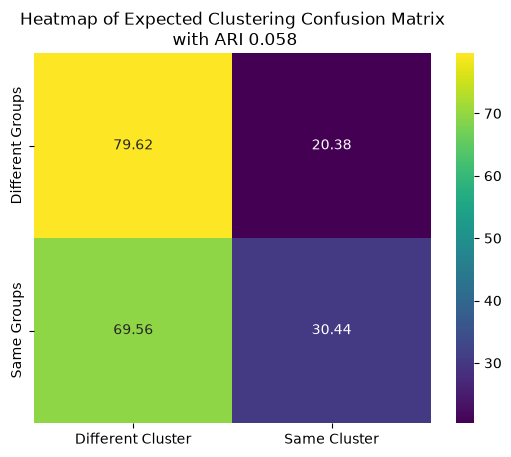

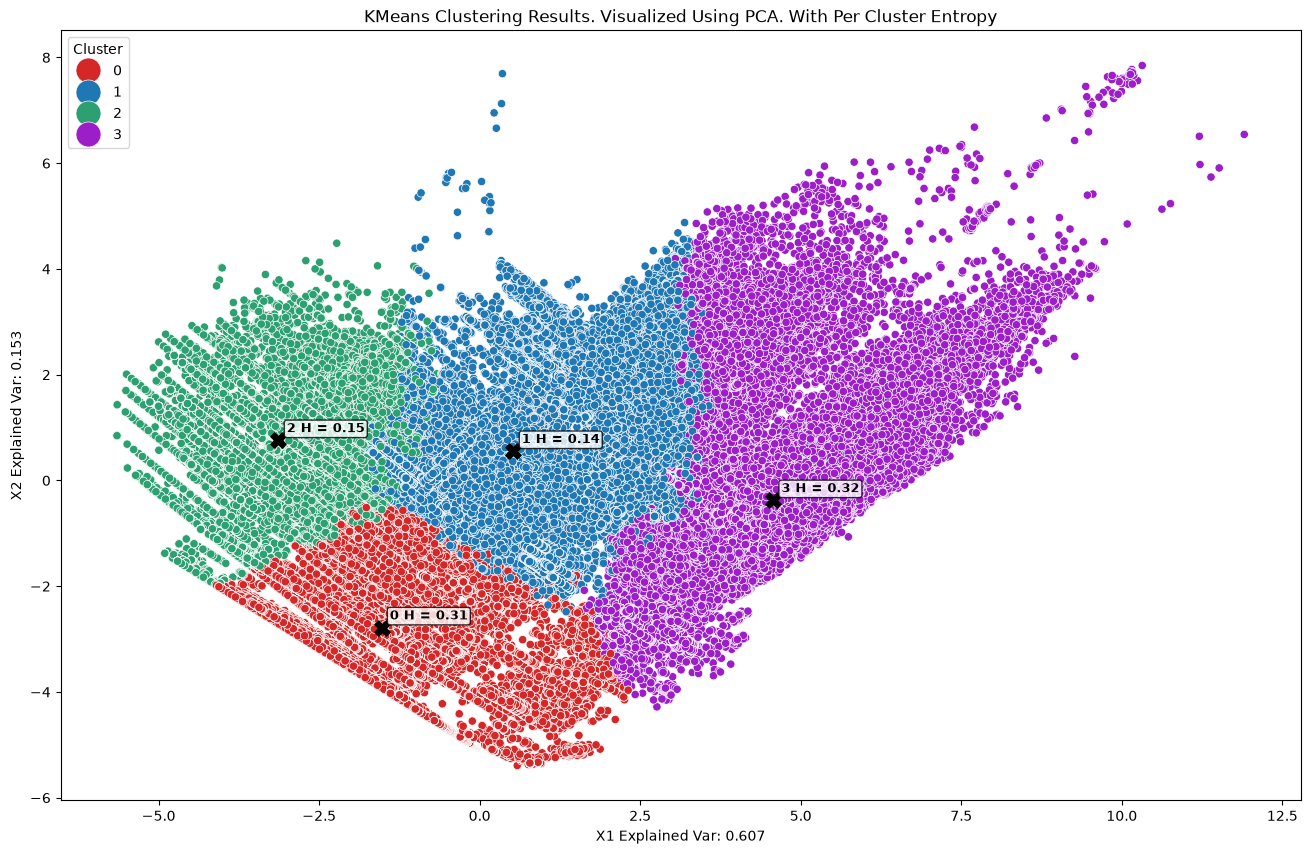

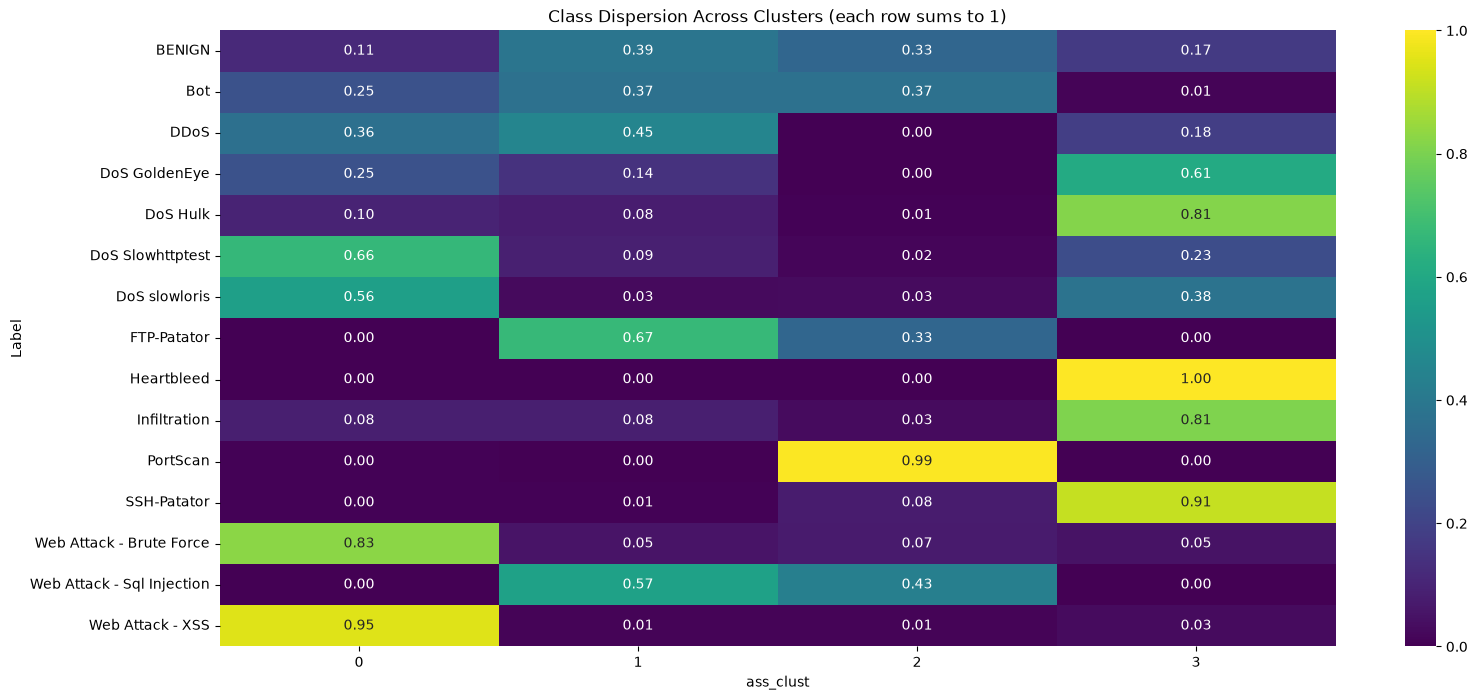

,Most Frequent In Cluster,Share of Cluster
ass_clust,,
0,BENIGN,0.76
1,BENIGN,0.91
2,BENIGN,0.88
3,BENIGN,0.67


(12823232.96112423, 0.3866628637571537, 0.05776014943087266)

In [217]:
hues_dict = {"0": "#d62728", "1": "#1f77b4", "2": "#2ca070", "3": "#9c1ec9"}
perform_clustering_exp(flow_clust_with_lab,expected_groups,hues_dict,perform_pca=True)

# Now using balanced classes to see how well the four clusters align with the theorized ones and how the seperation is looking. This is done on the full feature set.

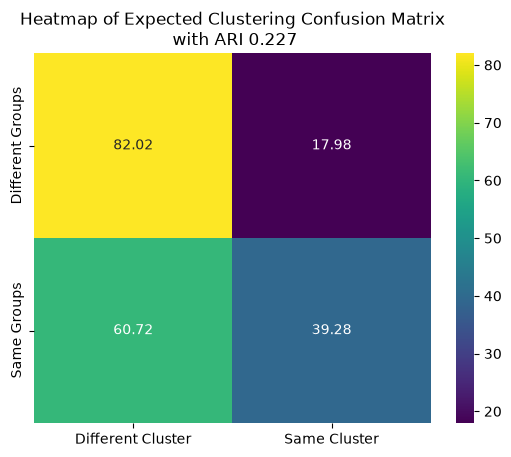

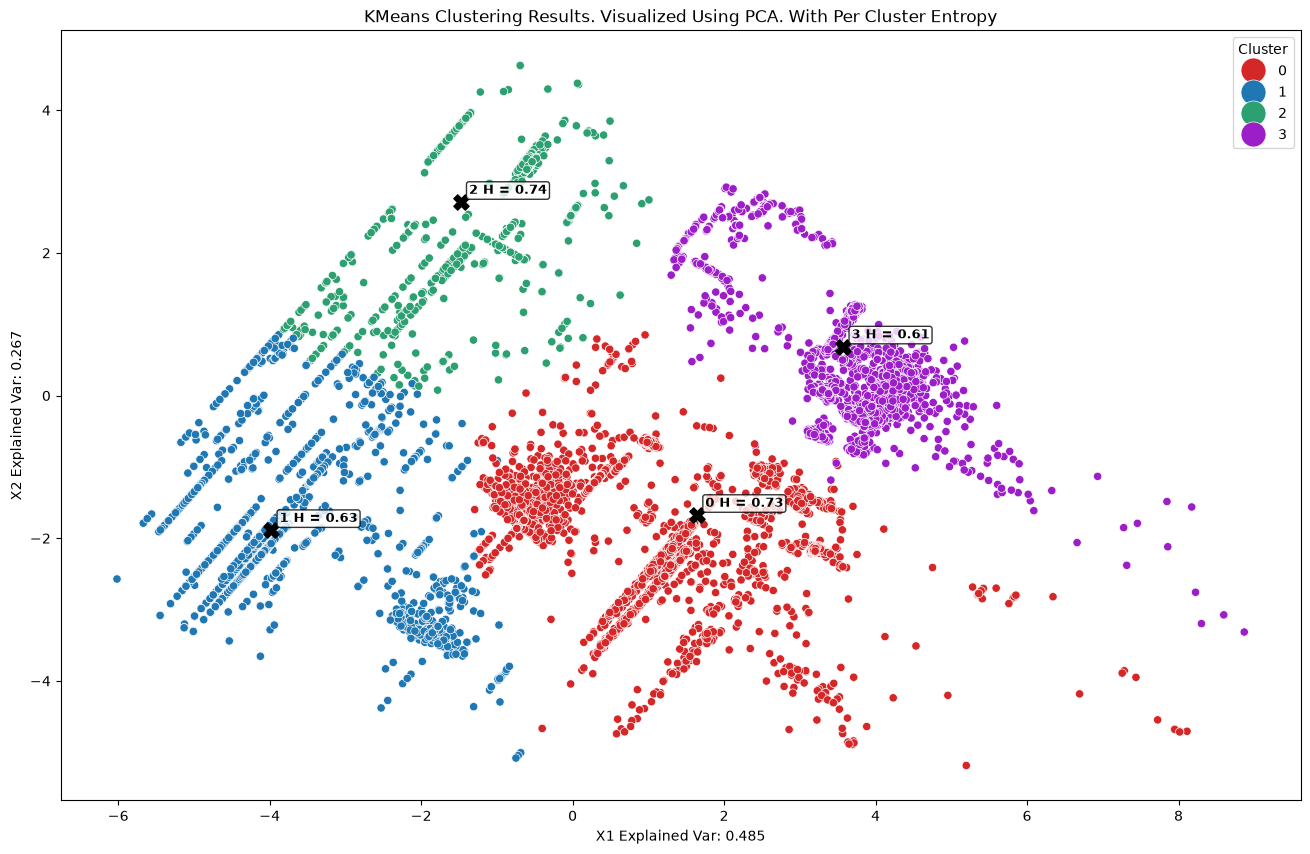

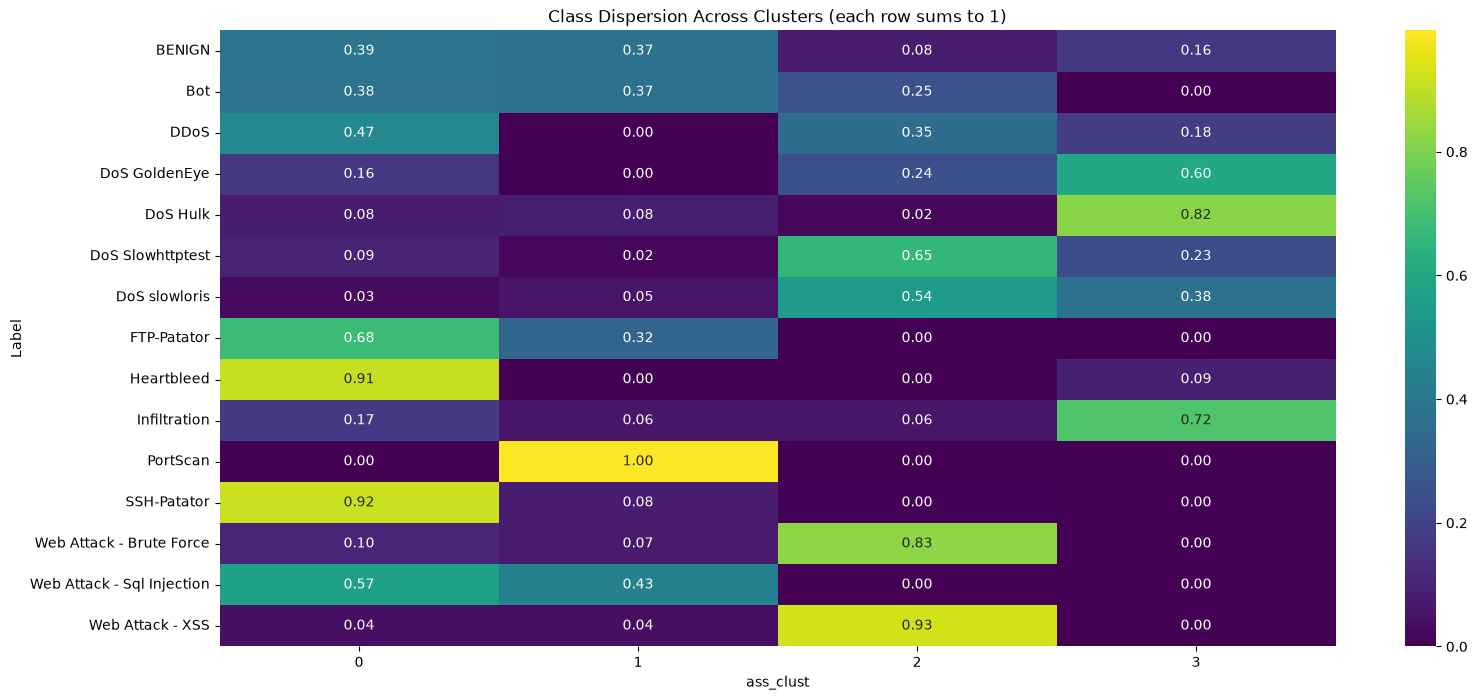

,Most Frequent In Cluster,Share of Cluster
ass_clust,,
0,SSH-Patator,0.28
1,PortScan,0.42
2,DoS Slowhttptest,0.21
3,DoS Hulk,0.34


In [218]:
# First balance the classes.
hues_dict = {"0": "#d62728", "1": "#1f77b4", "2": "#2ca070", "3": "#9c1ec9"}
balanced_df = balance_df(flow_clust_with_lab)
# Verify that the balanced df is not none.
if balance_df is None:
    print("Balancing the DF failed!!")
else:
    perform_clustering_exp(balanced_df,expected_groups,hues_dict,perform_pca=True)

# Now the next thing we are going to do is use the greedy column selection tool to drop redundant columns.

In [170]:
non_redudant_cols = construct_greedy_cols(15,flow_clust_with_lab.drop(columns=['Label']))
non_redudant_cols.append('Label')
non_redudant_cols

['Flow Duration',
 'Down/Up Ratio',
 'Packet Length Std',
 'Active Mean',
 'Bwd Packets/s',
 'Total Backward Packets',
 'Label']

In [174]:
reduced_cols_clust_df = flow_clust_with_lab[non_redudant_cols]
reduced_cols_clust_df.head(5)

,Flow Duration,Down/Up Ratio,Packet Length Std,Active Mean,Bwd Packets/s,Total Backward Packets,Label
0,-1.716896,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
1,-1.890385,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
2,-1.759146,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
3,-1.890385,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
4,-0.807313,-1.262621,0.476024,-0.505268,1.344518,0.402727,BENIGN


So this will be the set of features that we use in finding the most optimal k.

# Performing the K value tuning on the BALANCED dataset.

In [186]:
# First define the required color paldet though we will not use it here.
hues_dict = {"0": "#d62728", "1": "#1f77b4", "2": "#2ca070", "3": "#9c1ec9","4": "#E5C2D0"}

balanced_df = balance_df(reduced_cols_clust_df)
scores = []
k_searches = np.array(range(2,70))
# Verify that the balanced df is not none.
if balance_df is None:
    print("Balancing the DF failed!!")
else:
    for k in tqdm(k_searches):
        intertia_curr, sil_score_curr, ari_curr = perform_clustering_exp(balanced_df,expected_groups,hues_dict,perform_pca=False,show_pcm_vis=False,show_cross_tab=False,n_clust=k)
        scores.append([intertia_curr, sil_score_curr, ari_curr])

scores = np.array(scores)

100%|██████████| 68/68 [01:04<00:00,  1.06it/s]


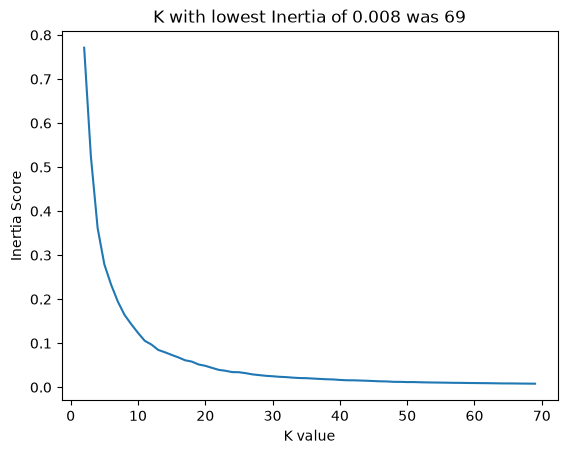

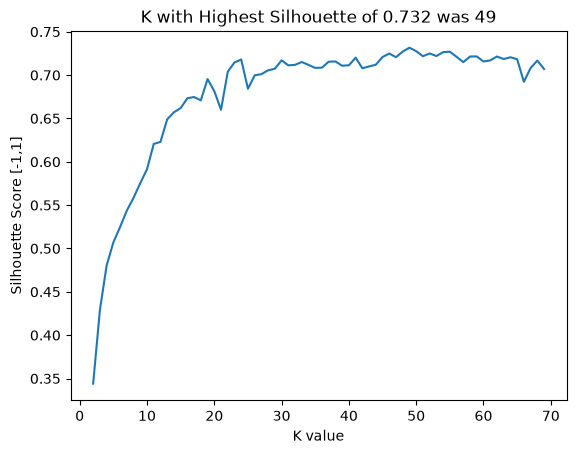

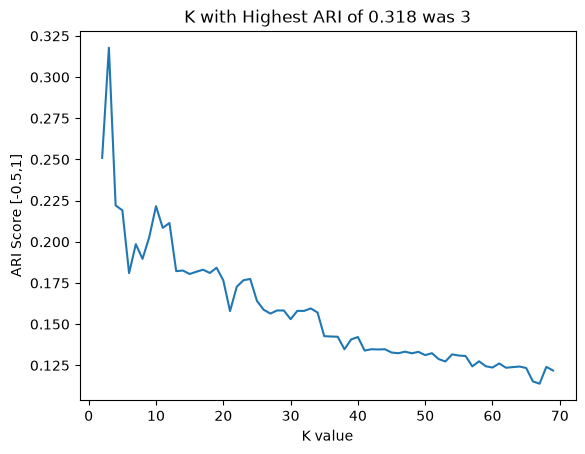

In [187]:
possible_sum_squares = balanced_df.shape[0]*(len(balanced_df.columns)-1)
sns.lineplot(x = k_searches , y=(scores[:,0]/possible_sum_squares))
plt.title(f"K with lowest Inertia of {(scores[:,0].min())/possible_sum_squares:.3f} was {k_searches[scores[:,0].argmin()]}")
plt.xlabel("K value")
plt.ylabel("Inertia Score")
plt.show()

sns.lineplot(x = k_searches , y=scores[:,1])
plt.title(f"K with Highest Silhouette of {scores[:,1].max():.3f} was {k_searches[np.abs(scores[:,1]).argmax()]}")
plt.xlabel("K value")
plt.ylabel("Silhouette Score [-1,1]")
plt.show()

sns.lineplot(x = k_searches , y=scores[:,2])
plt.title(f"K with Highest ARI of {scores[:,2].max():.3f} was {k_searches[scores[:,2].argmax()]}")
plt.xlabel("K value")
plt.ylabel("ARI Score [-0.5,1]")
plt.show()

# Now examining the serperation and performance with 20 clusters, doing this partially because it is still able to be visualized in the scatter plot as well.

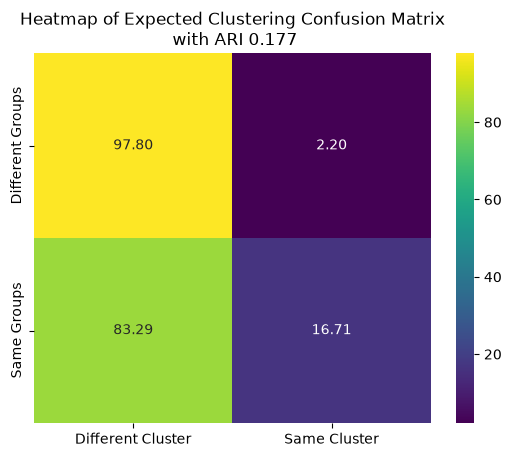

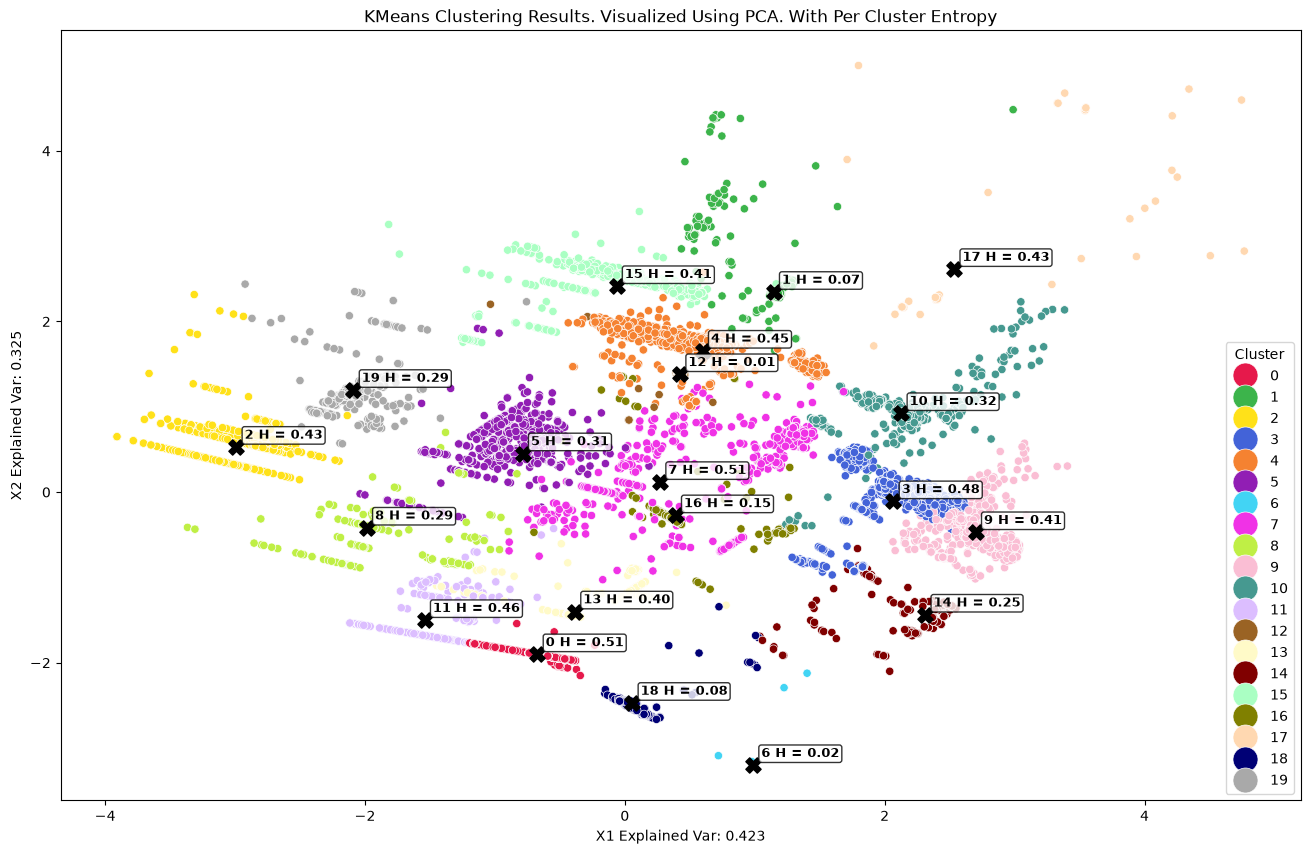

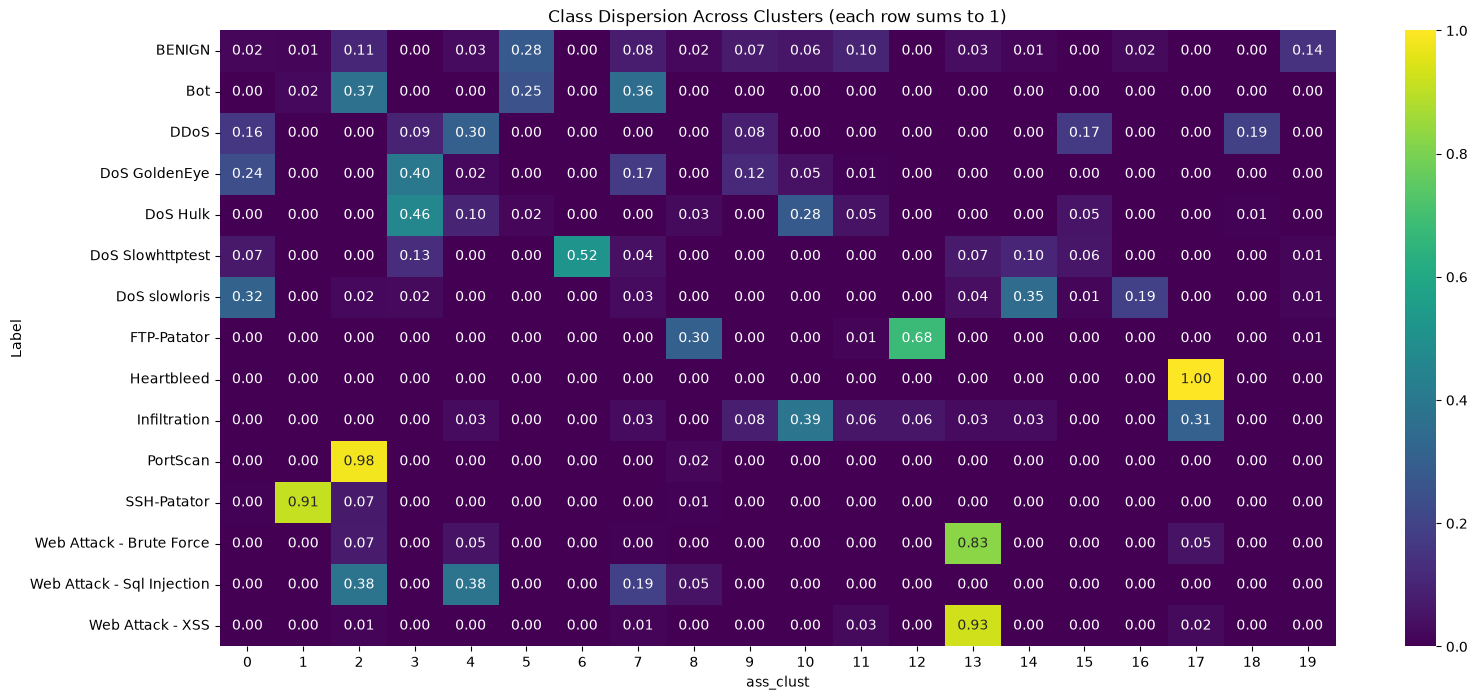

,Most Frequent In Cluster,Share of Cluster
ass_clust,,
0,DoS slowloris,0.39
1,SSH-Patator,0.96
2,PortScan,0.61
3,DoS Hulk,0.42
4,DDoS,0.60
5,BENIGN,0.51
6,DoS Slowhttptest,0.99
7,Bot,0.51
8,FTP-Patator,0.80


In [219]:
balanced_df = balance_df(reduced_cols_clust_df)
# Verify that the balanced df is not none.
if balance_df is None:
    print("Balancing the DF failed!!")
else:
    hues_dict = {
    "0": "#e6194B", "1": "#3cb44b", "2": "#ffe119", "3": "#4363d8", "4": "#f58231",
    "5": "#911eb4", "6": "#42d4f4", "7": "#f032e6", "8": "#bfef45", "9": "#fabed4",
    "10": "#469990", "11": "#dcbeff", "12": "#9A6324", "13": "#fffac8", "14": "#800000",
    "15": "#aaffc3", "16": "#808000", "17": "#ffd8b1", "18": "#000075", "19": "#a9a9a9",
    }

    perform_clustering_exp(balanced_df,expected_groups,hues_dict,perform_pca=True,n_clust=20)

# Conclusion